# Greenhouse Data Tracker
A beginner Python project that collects live temperature and humidity data from the Open-Meteo API, saves it to CSV, visualizes it, and gives simple plant-care alerts. It simulates an IoT greenhouse sensor.

**Tools:** Python, requests, matplotlib, REST API

In [5]:
import csv
import requests
import matplotlib.pyplot as plt

# Fetch live weather data (free API, no key needed) to simulate greenhouse sensors
url = 'https://api.open-meteo.com/v1/forecast'
params = {
    'latitude': 35.63,
    'longitude': 139.71,
    'hourly': 'temperature_2m,relative_humidity_2m',
    'forecast_days': 2,
}
data = requests.get(url, params=params).json()['hourly']
times = data['time']
temps = data['temperature_2m']
humidity = data['relative_humidity_2m']
print('Fetched', len(times), 'readings')

Fetched 48 readings


In [6]:
with open('greenhouse_data.csv', 'w', newline='') as f:
    writer = csv.writer(f)
    writer.writerow(['time', 'temperature_c', 'humidity_percent'])
    writer.writerows(zip(times, temps, humidity))
print('Saved greenhouse_data.csv')

Saved greenhouse_data.csv


In [7]:
if humidity[0] < 40:
    print('Alert: Humidity is low. Water the plants!')
elif temps[0] > 32:
    print('Alert: Too hot. Open the vents!')
else:
    print('Greenhouse conditions look good.')

Greenhouse conditions look good.


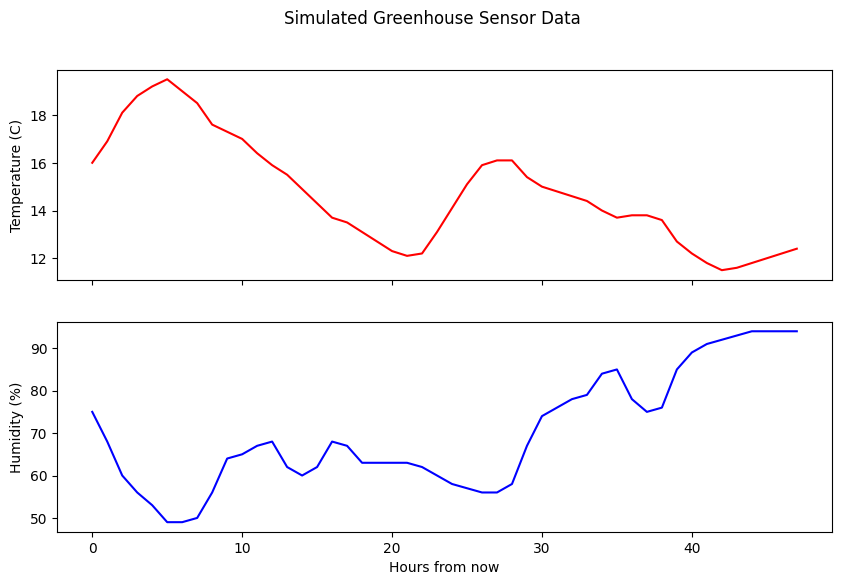

In [8]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax1.plot(temps, color='red')
ax1.set_ylabel('Temperature (C)')
ax2.plot(humidity, color='blue')
ax2.set_ylabel('Humidity (%)')
ax2.set_xlabel('Hours from now')
fig.suptitle('Simulated Greenhouse Sensor Data')
plt.show()